# DSC Gelar Rasa 2026 — Waste Image Classification

Notebook standalone untuk preliminary round DSC Gelar Rasa 2026.

Dataset train dari handbook berisi 1.920 gambar **tanpa label**, sedangkan test berisi 480 gambar. Karena tidak tersedia ground truth, notebook ini menggunakan pretrained MobileNetV2 yang dijalankan lokal sebagai feature extractor, kemudian K-Means untuk membentuk 8 kelompok.

**Catatan kejujuran metodologis:** akurasi 100% tidak dapat dijamin atau dihitung tanpa label train. Mapping cluster ke kategori harus diaudit oleh tim melalui grid visual sebelum submission. Tidak ada gambar yang dikirim ke API inference eksternal.

In [ ]:
# 1. Import dan konfigurasi
from pathlib import Path
import json, random
from collections import Counter-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path("Dataset DSC GelarRasa 2026")
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
OUTPUT_DIR = Path("outputs")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASSES = ["glass", "paper", "electronic", "metal", "plastic", "cardboard", "textile", "foodwaste"]

print("Train directory:", TRAIN_DIR)
print("Test directory :", TEST_DIR)
print("Classes        :", CLASSES)


Train directory: Dataset DSC GelarRasa 2026\train
Test directory : Dataset DSC GelarRasa 2026\test
Classes        : ['glass', 'paper', 'electronic', 'metal', 'plastic', 'cardboard', 'textile', 'foodwaste']


In [2]:
# 2. Load dan validasi dataset
train_paths = sorted([p for p in TRAIN_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS])
test_paths = sorted([p for p in TEST_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS])

assert len(train_paths) == 1920, f"Jumlah train tidak sesuai: {len(train_paths)}"
assert len(test_paths) == 480, f"Jumlah test tidak sesuai: {len(test_paths)}"

def check_images(paths):
    bad = []
    for path in paths:
        try:
            with Image.open(path) as image:
                image.verify()
        except (UnidentifiedImageError, OSError):
            bad.append(str(path))
    return bad

bad_images = check_images(train_paths + test_paths)
assert not bad_images, f"Gambar rusak: {bad_images[:5]}"
print(f"Valid: {len(train_paths)} train, {len(test_paths)} test, {len(bad_images)} rusak")


Valid: 1920 train, 480 test, 0 rusak


In [3]:
# 3. Ekstraksi fitur dengan MobileNetV2 lokal
# Pretrained model hanya digunakan sebagai feature extractor lokal,
# bukan sebagai layanan/API inference pihak ketiga.
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

feature_extractor = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
feature_extractor.trainable = False

def extract_features(paths, batch_size=32):
    batches = []
    for start in range(0, len(paths), batch_size):
        images = []
        for path in paths[start:start + batch_size]:
            image = tf.keras.utils.load_img(path, target_size=(224, 224))
            images.append(tf.keras.utils.img_to_array(image))
        batch = preprocess_input(np.asarray(images, dtype=np.float32))
        batches.append(feature_extractor.predict(batch, verbose=0))
    return np.concatenate(batches, axis=0)

all_paths = train_paths + test_paths
all_features = extract_features(all_paths)
train_features = all_features[:len(train_paths)]
test_features = all_features[len(train_paths):]
print("Train features:", train_features.shape)
print("Test features :", test_features.shape)


Train features: (1920, 1280)
Test features : (480, 1280)


In [4]:
# 4. Clustering train dan prediksi cluster test
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score

train_norm = normalize(train_features)
test_norm = normalize(test_features)

kmeans = KMeans(n_clusters=8, random_state=SEED, n_init=25)
train_clusters = kmeans.fit_predict(train_norm)
test_clusters = kmeans.predict(test_norm)
silhouette = silhouette_score(train_norm, train_clusters, sample_size=min(1000, len(train_norm)), random_state=SEED)

train_cluster_df = pd.DataFrame({"filename": [p.name for p in train_paths], "cluster": train_clusters})
test_cluster_df = pd.DataFrame({"filename": [p.name for p in test_paths], "cluster": test_clusters})
print("Silhouette score:", round(float(silhouette), 5))
print(train_cluster_df["cluster"].value_counts().sort_index())


c:\Users\Danu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


Silhouette score: 0.04082
cluster
0    192
1    470
2    264
3    176
4    173
5    280
6    175
7    190
Name: count, dtype: int64


## 5. Audit visual cluster

Periksa gambar-gambar berikut. Jika satu cluster berisi beberapa jenis sampah, maka mapping satu cluster ke satu kelas tidak valid dan akurasi tinggi tidak dapat dicapai hanya dengan K-Means.

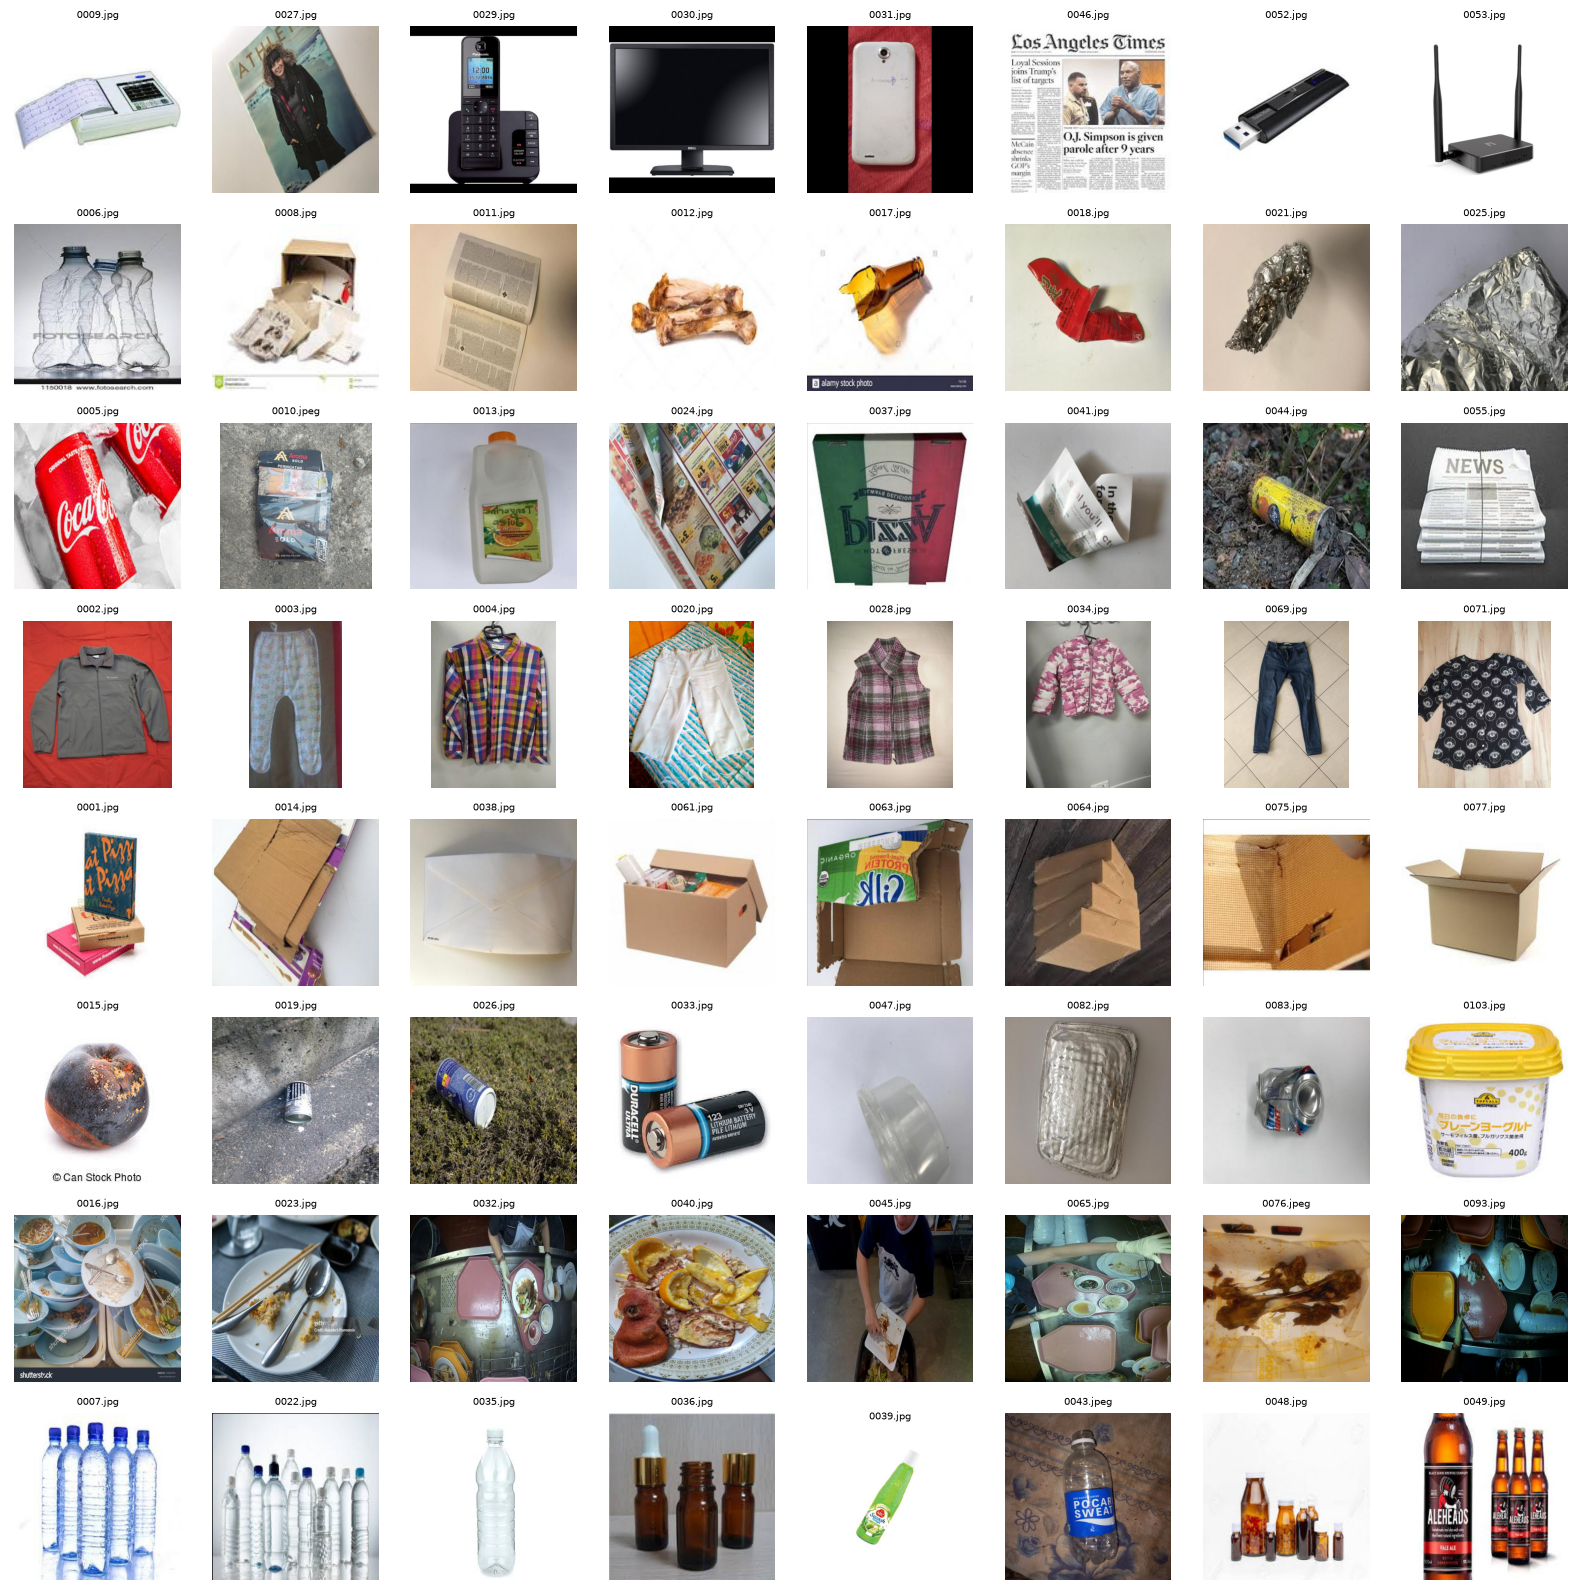

In [5]:
train_by_name = {p.name: p for p in train_paths}
fig, axes = plt.subplots(8, 8, figsize=(16, 16))
for cluster_id, row_axes in enumerate(axes):
    examples = train_cluster_df[train_cluster_df.cluster == cluster_id].head(8)
    for ax in row_axes:
        ax.axis("off")
    for ax, (_, row) in zip(row_axes, examples.iterrows()):
        ax.imshow(Image.open(train_by_name[row.filename]).convert("RGB"))
        ax.set_title(row.filename, fontsize=7)
    row_axes[0].set_ylabel(f"cluster {cluster_id}", fontsize=10)
plt.tight_layout()
plt.show()


## 6. Mapping cluster ke label kompetisi

Mapping di bawah adalah **hipotesis awal**, bukan ground truth. Ganti nilainya setelah audit visual. ID cluster K-Means dapat berubah jika fitur, seed, atau versi library berubah.

In [6]:
# Mapping awal dari pendekatan lama. WAJIB diaudit dan diperbaiki oleh tim.
CLUSTER_TO_CATEGORY = {
    0: "plastic",
    1: "paper",
    2: "glass",
    3: "metal",
    4: "cardboard",
    5: "textile",
    6: "electronic",
    7: "foodwaste",
}

assert set(CLUSTER_TO_CATEGORY.keys()) == set(range(8))
assert set(CLUSTER_TO_CATEGORY.values()) == set(CLASSES)
print(CLUSTER_TO_CATEGORY)


{0: 'plastic', 1: 'paper', 2: 'glass', 3: 'metal', 4: 'cardboard', 5: 'textile', 6: 'electronic', 7: 'foodwaste'}


In [7]:
# 7. Buat submission setelah mapping diaudit
OUTPUT_DIR.mkdir(exist_ok=True)
predicted_labels = [CLUSTER_TO_CATEGORY[int(cluster)] for cluster in test_clusters]
submission = pd.DataFrame({"filename": [p.name for p in test_paths], "predicted_label": predicted_labels})
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
train_cluster_df.to_csv(OUTPUT_DIR / "train_clusters.csv", index=False)
test_cluster_df.to_csv(OUTPUT_DIR / "test_clusters.csv", index=False)

report = {
    "train_images": len(train_paths),
    "test_images": len(test_paths),
    "n_clusters": 8,
    "silhouette_score": float(silhouette),
    "cluster_mapping": CLUSTER_TO_CATEGORY,
    "warning": "Train tidak memiliki label; akurasi 100% tidak dapat diverifikasi.",
}
(OUTPUT_DIR / "run_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
print(submission.head())
print("Saved:", OUTPUT_DIR / "submission.csv")


  filename predicted_label
0  001.jpg           paper
1  002.jpg      electronic
2  003.jpg      electronic
3  004.jpg         textile
4  005.jpg           glass
Saved: outputs\submission.csv


## Kesimpulan

Notebook ini sudah menghasilkan prediksi dan `outputs/submission.csv`, tetapi hasil tersebut bukan bukti akurasi 100%. Untuk meningkatkan peluang leaderboard, lakukan audit visual mapping, bandingkan beberapa seed/feature extractor, dan pastikan format kolom submission sama persis dengan contoh submission di halaman Kaggle.